# Task 1 – NLP Fundamentals, Pipeline & Data Exploration

In [289]:
# Import required libraries
import pandas as pd
import numpy as np
import re

# Load dataset
df = pd.read_csv('Tweets.csv')

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display first 5 rows
print("\nFirst 5 Rows:")
print(df[['text', 'airline_sentiment', 'airline']].head())

# Check missing values
print("\nMissing Values:")
print(df[['text', 'airline_sentiment', 'airline']].isnull().sum())

# Count duplicate tweets
print("\nDuplicate Tweets:",
      df['text'].duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Display updated shape
print("\nShape After Removing Duplicates:", df.shape)

# Display 5 raw tweets in full
print("\nFive Raw Tweets:")
for i, tweet in enumerate(df['text'].head(5), 1):
    print(f"\nTweet {i}: {tweet}")

Dataset Shape: (14640, 15)

First 5 Rows:
                                                text airline_sentiment  \
0                @VirginAmerica What @dhepburn said.           neutral   
1  @VirginAmerica plus you've added commercials t...          positive   
2  @VirginAmerica I didn't today... Must mean I n...           neutral   
3  @VirginAmerica it's really aggressive to blast...          negative   
4  @VirginAmerica and it's a really big bad thing...          negative   

          airline  
0  Virgin America  
1  Virgin America  
2  Virgin America  
3  Virgin America  
4  Virgin America  

Missing Values:
text                 0
airline_sentiment    0
airline              0
dtype: int64

Duplicate Tweets: 213

Shape After Removing Duplicates: (14604, 15)

Five Raw Tweets:

Tweet 1: @VirginAmerica What @dhepburn said.

Tweet 2: @VirginAmerica plus you've added commercials to the experience... tacky.

Tweet 3: @VirginAmerica I didn't today... Must mean I need to take another tr

In [290]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

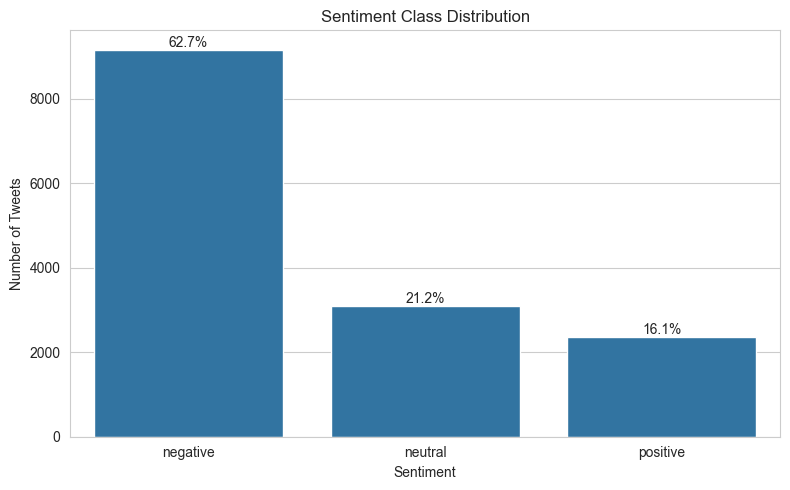

In [291]:
# Calculate sentiment counts
sentiment_counts = df['airline_sentiment'].value_counts()

# Calculate percentages
sentiment_percent = (
    df['airline_sentiment'].value_counts(normalize=True) * 100
)

# Plot
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")

# Add percentages
for i, value in enumerate(sentiment_counts.values):
    ax.text(
        i,
        value,
        f"{sentiment_percent.iloc[i]:.1f}%",
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

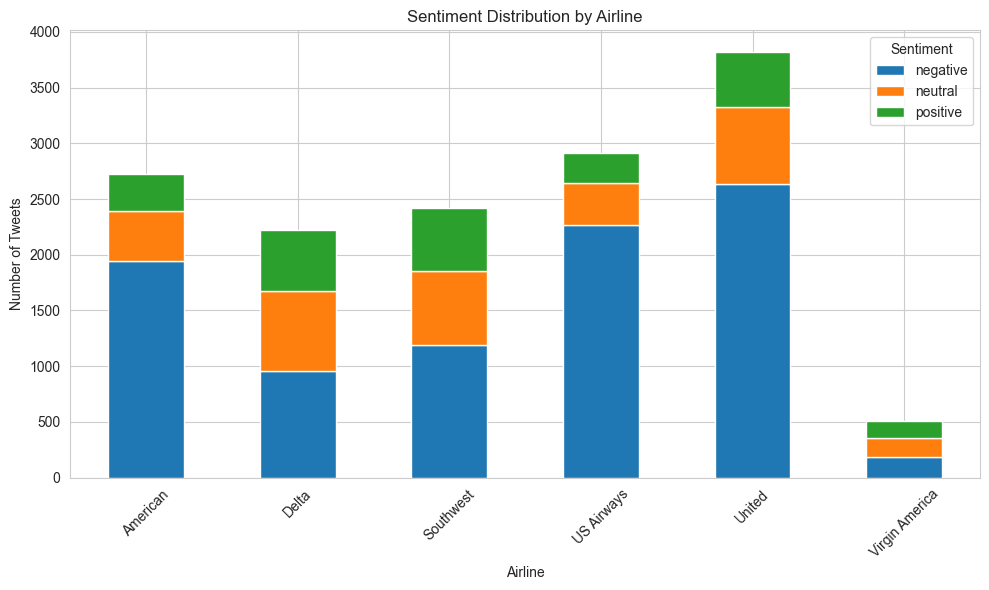

In [292]:
# Group sentiment by airline
airline_sentiment = pd.crosstab(
    df['airline'],
    df['airline_sentiment']
)

# Plot stacked bar chart
airline_sentiment.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sentiment Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")

plt.tight_layout()
plt.show()

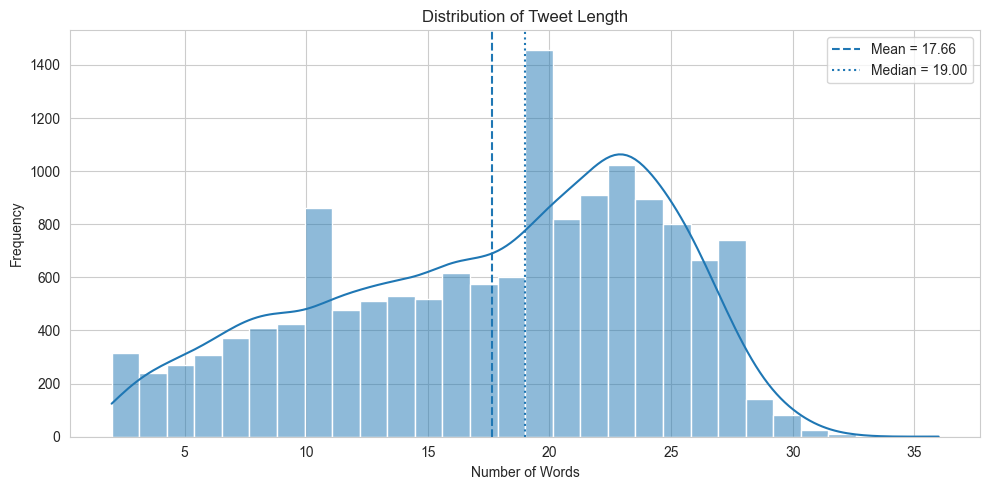

Mean Tweet Length: 17.655847712955353
Median Tweet Length: 19.0


In [293]:
# Calculate tweet length in words
df['tweet_length'] = df['text'].fillna('').apply(
    lambda x: len(x.split())
)

# Calculate mean and median
mean_length = df['tweet_length'].mean()
median_length = df['tweet_length'].median()

# Plot histogram
plt.figure(figsize=(10, 5))

sns.histplot(
    df['tweet_length'],
    bins=30,
    kde=True
)

plt.axvline(
    mean_length,
    linestyle='--',
    label=f'Mean = {mean_length:.2f}'
)

plt.axvline(
    median_length,
    linestyle=':',
    label=f'Median = {median_length:.2f}'
)

plt.title("Distribution of Tweet Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

print("Mean Tweet Length:", mean_length)
print("Median Tweet Length:", median_length)

In [294]:
# Select tweets demonstrating NLP challenges

# 1. Negation
negation_tweets = df[
    df['text'].str.contains(
        r'\b(not|no|never|nor|isn.t|wasn.t|don.t)\b',
        case=False,
        na=False,
        regex=True
    )
]

# 2. Sarcasm or irony
sarcasm_tweets = df[
    df['text'].str.contains(
        r'\b(thanks for nothing|great job|yeah right|love that|wonderful)\b',
        case=False,
        na=False,
        regex=True
    )
]

# 3. Slang or misspelling
slang_tweets = df[
    df['text'].str.contains(
        r'\b(lol|omg|wtf|pls|thx|u|ur|gr8|gonna|wanna)\b',
        case=False,
        na=False,
        regex=True
    )
]

# 4. Emojis or special symbols
emoji_tweets = df[
    df['text'].str.contains(
        r'[^\x00-\x7F]',
        na=False,
        regex=True
    )
]

# 5. Mixed or difficult-to-label sentiment
mixed_tweets = df[
    df['text'].str.contains(
        r'\b(good|great|happy|love|thank)\b',
        case=False,
        na=False
    ) &
    df['text'].str.contains(
        r'\b(bad|delay|cancel|late|terrible|worst)\b',
        case=False,
        na=False
    )
]

# Display actual examples from the dataset
categories = {
    "Negation": negation_tweets,
    "Sarcasm / Irony": sarcasm_tweets,
    "Slang / Misspelling": slang_tweets,
    "Emojis / Special Symbols": emoji_tweets,
    "Difficult to Label": mixed_tweets
}

for category, data in categories.items():
    print("\n==========", category, "==========")

    if len(data) > 0:
        print(
            data[['text', 'airline_sentiment']]
            .head(5)
            .to_string(index=False)
        )
    else:
        print("No matching tweets found.")

C:\Users\patel\AppData\Local\Temp\ipykernel_14020\4022256565.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['text'].str.contains(
C:\Users\patel\AppData\Local\Temp\ipykernel_14020\4022256565.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['text'].str.contains(
C:\Users\patel\AppData\Local\Temp\ipykernel_14020\4022256565.py:25: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['text'].str.contains(
C:\Users\patel\AppData\Local\Temp\ipykernel_14020\4022256565.py:44: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['text'].str.contains(



========== Negation ==========
                                                                                                                                                        text airline_sentiment
                                            @VirginAmerica status match program.  I applied and it's been three weeks.  Called and emailed with no response.          negative
                                                                                     @VirginAmerica do you miss me? Don't worry we'll be together very soon.           neutral
@VirginAmerica hi! I just bked a cool birthday trip with you, but i can't add my elevate no. cause i entered my middle name during Flight Booking Problems 😢          negative
                              @VirginAmerica help, left expensive headphones on flight 89 IAD to LAX today. Seat 2A. No one answering L&amp;F number at LAX!          negative
                                                                        @VirginAmerica Your c

C:\Users\patel\AppData\Local\Temp\ipykernel_14020\4022256565.py:49: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['text'].str.contains(


# Task 2 – Text Cleaning with RegEx & Tokenisation

In [295]:
import re

# 1. URL removal
text = "Visit https://www.airindia.com for details"
print(re.sub(r'https?://\S+', '', text))

# 2. @Mention removal
text = "Hello @rahul welcome to our page"
print(re.sub(r'@\w+', '', text))

# 3. Hashtag handling
text = "I love #AirIndia and #Travel"
print(re.sub(r'#(\w+)', r'\1', text))

# 4. Number removal
text = "Flight 123 delayed by 2 hours"
print(re.sub(r'\d+', '', text))

# 5. Punctuation removal
text = "Flight is delayed!!! Very bad."
print(re.sub(r'[^a-z\s]', '', text.lower()))

# 6. Repeated whitespace removal
text = "Flight     is     delayed"
print(re.sub(r'\s+', ' ', text).strip())

Visit  for details
Hello  welcome to our page
I love AirIndia and Travel
Flight  delayed by  hours
flight is delayed very bad
Flight is delayed


In [296]:
def clean_text(s):
    if pd.isna(s):
        return ""

    s = str(s)

    # Convert to lowercase
    s = s.lower()

    # Remove URLs
    s = re.sub(r'https?://\S+|www\.\S+', '', s)

    # Remove @mentions
    s = re.sub(r'@\w+', '', s)

    # Keep hashtag word but remove #
    s = re.sub(r'#(\w+)', r'\1', s)

    # Remove numbers and punctuation
    s = re.sub(r'[^a-z\s]', ' ', s)

    # Remove extra spaces
    s = re.sub(r'\s+', ' ', s).strip()

    return s


# Create new cleaned text column
df['clean_text'] = df['text'].apply(clean_text)

# Display raw and cleaned tweets
print(df[['text', 'clean_text']].head(5).to_string(index=False))

                                                                                                                          text                                                                                                 clean_text
                                                                                           @VirginAmerica What @dhepburn said.                                                                                                  what said
                                                      @VirginAmerica plus you've added commercials to the experience... tacky.                                                      plus you ve added commercials to the experience tacky
                                                       @VirginAmerica I didn't today... Must mean I need to take another trip!                                                       i didn t today must mean i need to take another trip
@VirginAmerica it's really aggressive to blast obnoxious "entert

In [297]:
# Count empty tweets after cleaning
empty_count = (df['clean_text'] == '').sum()

print("Empty tweets after cleaning:", empty_count)

# Display empty tweets
print(df[df['clean_text'] == ''][['text', 'clean_text']].head())

# Remove empty cleaned tweets
df = df[df['clean_text'] != ''].copy()

print("Dataset shape after removing empty tweets:", df.shape)

Empty tweets after cleaning: 0
Empty DataFrame
Columns: [text, clean_text]
Index: []
Dataset shape after removing empty tweets: (14604, 17)


In [298]:
pip install nltk


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\patel\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [299]:
import nltk
from nltk.corpus import stopwords

# Download stopwords
nltk.download('stopwords')

# Load English stopwords
stop_words = set(stopwords.words('english'))

# Preserve negation words
negation_words = {'no', 'not', 'nor', 'never'}

stop_words = stop_words - negation_words

# Tokenisation function
def tokenize_text(text):
    return text.split()

# Stop-word removal function
def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word not in stop_words
    ]

# Example
sentence = "not happy with the delay"

tokens = tokenize_text(sentence)
filtered_tokens = remove_stopwords(tokens)

print("Original Sentence:", sentence)
print("Tokens:", tokens)
print("After Stop-word Removal:", filtered_tokens)

Original Sentence: not happy with the delay
Tokens: ['not', 'happy', 'with', 'the', 'delay']
After Stop-word Removal: ['not', 'happy', 'delay']


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\patel/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [300]:
# Tokenise cleaned tweets
df['tokens'] = df['clean_text'].apply(tokenize_text)

# Remove stop-words
df['filtered_tokens'] = df['tokens'].apply(remove_stopwords)

# Display examples
print(df[['clean_text', 'tokens', 'filtered_tokens']].head(5))

                                          clean_text  \
0                                          what said   
1  plus you ve added commercials to the experienc...   
2  i didn t today must mean i need to take anothe...   
3  it s really aggressive to blast obnoxious ente...   
4           and it s a really big bad thing about it   

                                              tokens  \
0                                       [what, said]   
1  [plus, you, ve, added, commercials, to, the, e...   
2  [i, didn, t, today, must, mean, i, need, to, t...   
3  [it, s, really, aggressive, to, blast, obnoxio...   
4  [and, it, s, a, really, big, bad, thing, about...   

                                     filtered_tokens  
0                                             [said]  
1      [plus, added, commercials, experience, tacky]  
2     [today, must, mean, need, take, another, trip]  
3  [really, aggressive, blast, obnoxious, enterta...  
4                          [really, big, bad, thing

In [301]:
from collections import Counter

# Vocabulary before cleaning
raw_tokens = []

for tweet in df['text'].dropna():
    raw_tokens.extend(str(tweet).lower().split())

vocab_before = set(raw_tokens)

# Vocabulary after cleaning and stop-word removal
clean_tokens = []

for tokens in df['filtered_tokens']:
    clean_tokens.extend(tokens)

vocab_after = set(clean_tokens)

print("Vocabulary Before Cleaning:", len(vocab_before))
print("Vocabulary After Cleaning:", len(vocab_after))

print("Vocabulary Reduced By:",
      len(vocab_before) - len(vocab_after))

Vocabulary Before Cleaning: 26840
Vocabulary After Cleaning: 11033
Vocabulary Reduced By: 15807


In [302]:
sentiments = ['negative', 'neutral', 'positive']

for sentiment in sentiments:

    words = []

    sentiment_data = df[
        df['airline_sentiment'] == sentiment
    ]

    for tokens in sentiment_data['filtered_tokens']:
        words.extend(tokens)

    word_counts = Counter(words)

    print("\nTop 20 Words -", sentiment.upper())

    for word, count in word_counts.most_common(20):
        print(word, ":", count)


Top 20 Words - NEGATIVE
flight : 2952
not : 1357
no : 1321
get : 990
cancelled : 921
service : 748
hours : 656
help : 618
hold : 611
customer : 611
time : 597
plane : 530
delayed : 504
amp : 503
us : 502
still : 492
call : 461
hour : 457
flightled : 445
one : 441

Top 20 Words - NEUTRAL
flight : 614
get : 238
please : 182
help : 170
flights : 169
need : 163
thanks : 157
not : 149
dm : 132
would : 123
no : 119
us : 112
tomorrow : 108
fleek : 107
know : 103
fleet : 103
cancelled : 100
time : 98
amp : 98
way : 95

Top 20 Words - POSITIVE
thanks : 606
thank : 454
flight : 382
great : 235
service : 162
love : 134
customer : 114
get : 114
guys : 109
much : 108
good : 107
best : 105
got : 100
awesome : 98
time : 97
us : 90
help : 84
today : 83
amp : 82
airline : 79


In [303]:
word_counts = Counter(clean_tokens)

# Words occurring exactly once
unique_words = [
    word for word, count in word_counts.items()
    if count == 1
]

print("Total Unique Words:", len(word_counts))

print("Words Appearing Only Once:", len(unique_words))

print("\nExamples:", unique_words[:20])

Total Unique Words: 11033
Words Appearing Only Once: 5453

Examples: ['tacky', 'worm', 'parody', 'graphics', 'minimal', 'iconography', 'seductive', 'daystogo', 'graphic', 'hipster', 'vents', 'noair', 'sfotobos', 'noob', 'sendambien', 'andchexmix', 'bked', 'moodlight', 'calming', 'hollywood']


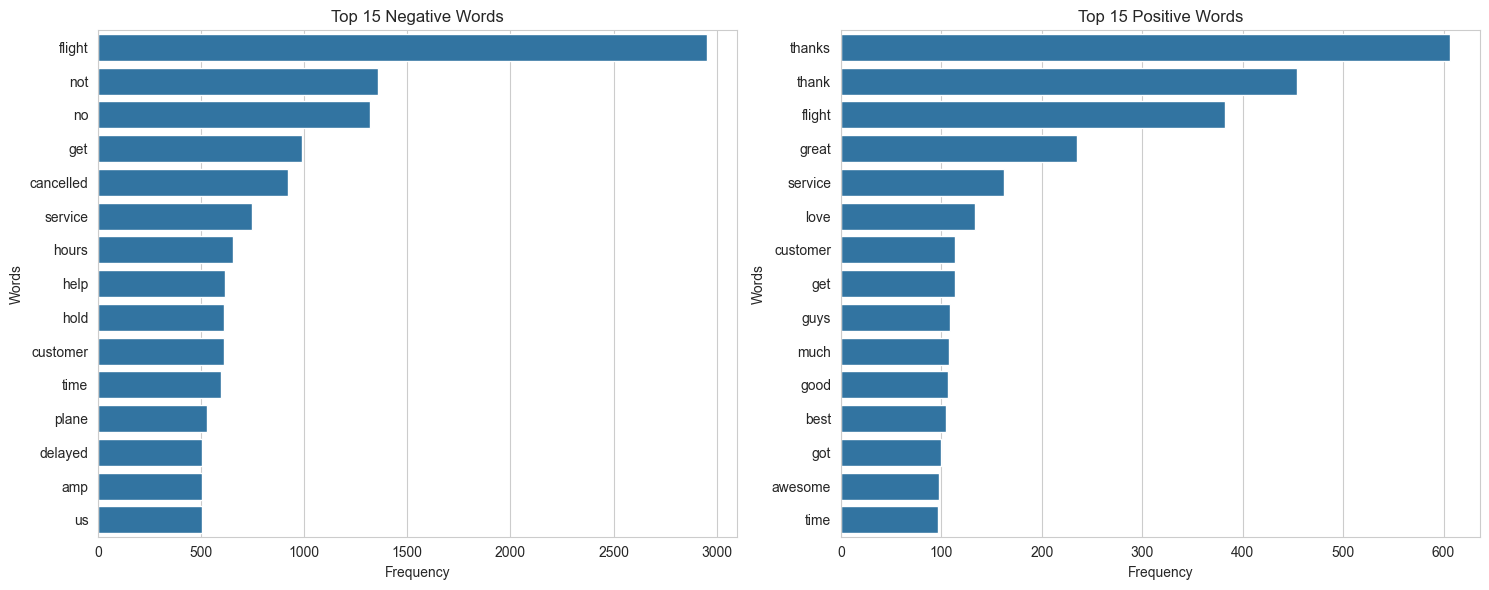

In [304]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, sentiment in zip(axes, ['negative', 'positive']):

    words = []

    sentiment_data = df[
        df['airline_sentiment'] == sentiment
    ]

    for tokens in sentiment_data['filtered_tokens']:
        words.extend(tokens)

    top_words = Counter(words).most_common(15)

    word_df = pd.DataFrame(
        top_words,
        columns=['Word', 'Frequency']
    )

    sns.barplot(
        data=word_df,
        x='Frequency',
        y='Word',
        ax=ax
    )

    ax.set_title(f"Top 15 {sentiment.title()} Words")
    ax.set_xlabel("Frequency")
    ax.set_ylabel("Words")

plt.tight_layout()
plt.show()

# Task 3 – Different NLP Approaches: Heuristic & API-Based

In [305]:
positive_words = {
    'good', 'great', 'excellent', 'amazing', 'awesome',
    'happy', 'love', 'wonderful', 'best', 'fantastic',
    'thanks', 'thank', 'helpful', 'friendly', 'comfortable',
    'smooth', 'perfect', 'appreciate', 'nice', 'quick',
    'fast', 'professional', 'polite', 'easy', 'enjoyed',
    'delightful', 'outstanding', 'reliable', 'impressed',
    'resolved'
}

negative_words = {
    'bad', 'worst', 'terrible', 'awful', 'horrible',
    'delay', 'delayed', 'cancelled', 'canceled', 'rude',
    'poor', 'late', 'lost', 'missing', 'angry',
    'unhappy', 'disappointed', 'disappointing', 'slow',
    'broken', 'problem', 'issue', 'never', 'refund',
    'waiting', 'frustrating', 'unhelpful', 'uncomfortable',
    'expensive', 'failure'
}

print("Positive words:", len(positive_words))
print("Negative words:", len(negative_words))

Positive words: 30
Negative words: 30


In [306]:
negation_words = {'not', 'no', 'never', 'nor'}

def heuristic_sentiment(text):

    words = text.lower().split()

    positive_score = 0
    negative_score = 0

    for i, word in enumerate(words):

        # Check previous two words for negation
        previous_words = words[max(0, i-2):i]

        is_negated = any(
            w in negation_words for w in previous_words
        )

        if word in positive_words:

            if is_negated:
                negative_score += 1
            else:
                positive_score += 1

        elif word in negative_words:

            if is_negated:
                positive_score += 1
            else:
                negative_score += 1

    if positive_score > negative_score:
        sentiment = 'positive'

    elif negative_score > positive_score:
        sentiment = 'negative'

    else:
        sentiment = 'neutral'

    return sentiment, positive_score, negative_score

In [307]:
# Select five tweets from the dataset
sample_tweets = df.sample(
    n=5,
    random_state=42
)

for _, row in sample_tweets.iterrows():

    prediction, pos, neg = heuristic_sentiment(
        row['clean_text']
    )

    print("\nTweet:", row['text'])
    print("Actual Sentiment:", row['airline_sentiment'])
    print("Predicted Sentiment:", prediction)
    print("Positive Score:", pos)
    print("Negative Score:", neg)


Tweet: @VirginAmerica to jump into the Dallas-Austin market - @Dallas_News http://t.co/EwwGi97gdx
Actual Sentiment: neutral
Predicted Sentiment: neutral
Positive Score: 0
Negative Score: 0

Tweet: @united nice. I wonder how you pick who to respond to? Maybe only happy customers are easier. I wonder how many of those you have left.
Actual Sentiment: negative
Predicted Sentiment: positive
Positive Score: 2
Negative Score: 0

Tweet: @USAirways BF has been stuck in CLT all day. Is the lounge offering free "This weather sucks &amp; we all want to cry" tequila shots?
Actual Sentiment: negative
Predicted Sentiment: neutral
Positive Score: 0
Negative Score: 0

Tweet: @USAirways horrible service, wrong plane arrived, many confirmed passengers could not get on flight we paid for due to lack of seats flight
Actual Sentiment: negative
Predicted Sentiment: negative
Positive Score: 0
Negative Score: 1

Tweet: @AmericanAir. You neglected to mention the $200 fee per ticket.  I had a medical reason an

In [308]:
import nltk

# Download VADER lexicon
nltk.download('vader_lexicon')

from nltk.sentiment import SentimentIntensityAnalyzer

# Create VADER analyzer
sia = SentimentIntensityAnalyzer()


def vader_sentiment(text):

    scores = sia.polarity_scores(str(text))

    compound = scores['compound']

    if compound >= 0.05:
        sentiment = 'positive'

    elif compound <= -0.05:
        sentiment = 'negative'

    else:
        sentiment = 'neutral'

    return sentiment, scores


# Test five tweets
for _, row in sample_tweets.iterrows():

    prediction, scores = vader_sentiment(row['text'])

    print("\nTweet:", row['text'])
    print("Actual:", row['airline_sentiment'])
    print("Predicted:", prediction)
    print("VADER Scores:", scores)


Tweet: @VirginAmerica to jump into the Dallas-Austin market - @Dallas_News http://t.co/EwwGi97gdx
Actual: neutral
Predicted: neutral
VADER Scores: {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}

Tweet: @united nice. I wonder how you pick who to respond to? Maybe only happy customers are easier. I wonder how many of those you have left.
Actual: negative
Predicted: positive
VADER Scores: {'neg': 0.0, 'neu': 0.693, 'pos': 0.307, 'compound': 0.8519}

Tweet: @USAirways BF has been stuck in CLT all day. Is the lounge offering free "This weather sucks &amp; we all want to cry" tequila shots?
Actual: negative
Predicted: negative
VADER Scores: {'neg': 0.236, 'neu': 0.621, 'pos': 0.143, 'compound': -0.4588}

Tweet: @USAirways horrible service, wrong plane arrived, many confirmed passengers could not get on flight we paid for due to lack of seats flight
Actual: negative
Predicted: negative
VADER Scores: {'neg': 0.308, 'neu': 0.692, 'pos': 0.0, 'compound': -0.836}

Tweet: @AmericanAir. You

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\patel/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [309]:
from sklearn.model_selection import train_test_split

# Input and target
X = df['clean_text']
y = df['airline_sentiment']

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Size:", len(X_train))
print("Testing Size:", len(X_test))

print("\nTraining Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Distribution:")
print(y_test.value_counts(normalize=True))

Training Size: 11683
Testing Size: 2921

Training Distribution:
airline_sentiment
negative    0.627151
neutral     0.211675
positive    0.161174
Name: proportion, dtype: float64

Testing Distribution:
airline_sentiment
negative    0.627182
neutral     0.211571
positive    0.161246
Name: proportion, dtype: float64


In [310]:
# Heuristic predictions
y_pred_heuristic = [
    heuristic_sentiment(text)[0]
    for text in X_test
]

# VADER predictions
y_pred_vader = [
    vader_sentiment(text)[0]
    for text in df.loc[X_test.index, 'text']
]

print("Heuristic predictions completed.")
print("VADER predictions completed.")

Heuristic predictions completed.
VADER predictions completed.


In [311]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Heuristic evaluation
print("========== HEURISTIC RESULTS ==========")

print("Accuracy:",
      accuracy_score(y_test, y_pred_heuristic))

print("Macro-F1:",
      f1_score(y_test, y_pred_heuristic, average='macro'))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_heuristic,
    zero_division=0
))

# VADER evaluation
print("\n========== VADER RESULTS ==========")

print("Accuracy:",
      accuracy_score(y_test, y_pred_vader))

print("Macro-F1:",
      f1_score(y_test, y_pred_vader, average='macro'))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_vader,
    zero_division=0
))

========== HEURISTIC RESULTS ==========
Accuracy: 0.49743238616912017
Macro-F1: 0.5234195069433423

Classification Report:
              precision    recall  f1-score   support

    negative       0.92      0.35      0.50      1832
     neutral       0.29      0.82      0.43       618
    positive       0.61      0.66      0.63       471

    accuracy                           0.50      2921
   macro avg       0.61      0.61      0.52      2921
weighted avg       0.74      0.50      0.51      2921


========== VADER RESULTS ==========
Accuracy: 0.5374871619308456
Macro-F1: 0.507795174509307

Classification Report:
              precision    recall  f1-score   support

    negative       0.90      0.48      0.63      1832
     neutral       0.39      0.44      0.41       618
    positive       0.33      0.88      0.48       471

    accuracy                           0.54      2921
   macro avg       0.54      0.60      0.51      2921
weighted avg       0.70      0.54      0.56      292

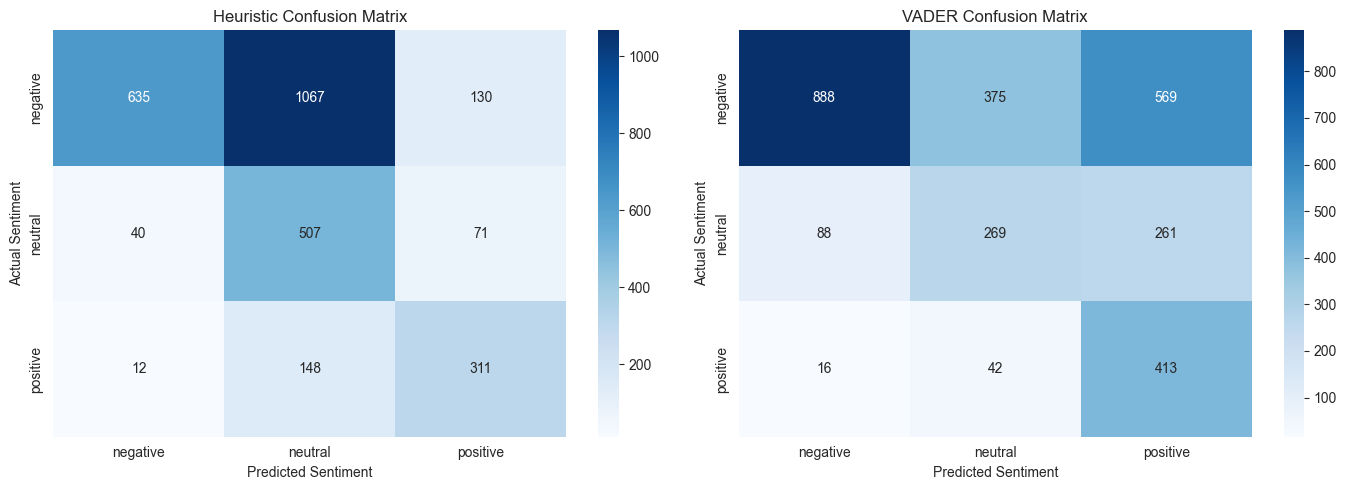

In [312]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = ['negative', 'neutral', 'positive']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, predictions, title in zip(
    axes,
    [y_pred_heuristic, y_pred_vader],
    ['Heuristic Confusion Matrix', 'VADER Confusion Matrix']
):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Predicted Sentiment')
    ax.set_ylabel('Actual Sentiment')

plt.tight_layout()
plt.show()

In [313]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score

results = pd.DataFrame({
    'Approach': ['Heuristic', 'VADER'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_heuristic),
        accuracy_score(y_test, y_pred_vader)
    ],
    'Macro-F1': [
        f1_score(y_test, y_pred_heuristic, average='macro'),
        f1_score(y_test, y_pred_vader, average='macro')
    ],
    'Macro Precision': [
        precision_score(y_test, y_pred_heuristic,
                        average='macro', zero_division=0),
        precision_score(y_test, y_pred_vader,
                        average='macro', zero_division=0)
    ],
    'Macro Recall': [
        recall_score(y_test, y_pred_heuristic,
                     average='macro', zero_division=0),
        recall_score(y_test, y_pred_vader,
                     average='macro', zero_division=0)
    ]
})

print(results.round(4).to_string(index=False))

 Approach  Accuracy  Macro-F1  Macro Precision  Macro Recall
Heuristic    0.4974    0.5234           0.6087        0.6091
    VADER    0.5375    0.5078           0.5399        0.5989


In [314]:
# Create error analysis DataFrame
error_df = pd.DataFrame({
    'Tweet': df.loc[X_test.index, 'text'],
    'True Sentiment': y_test,
    'Heuristic Prediction': y_pred_heuristic,
    'VADER Prediction': y_pred_vader
})

# Heuristic errors
heuristic_errors = error_df[
    error_df['True Sentiment'] !=
    error_df['Heuristic Prediction']
]

# VADER errors
vader_errors = error_df[
    error_df['True Sentiment'] !=
    error_df['VADER Prediction']
]

print("========== HEURISTIC ERRORS ==========")
print(heuristic_errors.head(2).to_string(index=False))

print("\n========== VADER ERRORS ==========")
print(vader_errors.head(2).to_string(index=False))

========== HEURISTIC ERRORS ==========
                                                                                                                                       Tweet True Sentiment Heuristic Prediction VADER Prediction
@united I appreciate the immediate offer, but suspect it is more long-term issue/not simple fix. Also, ski/bootbag policy is awkward at best       negative             positive         positive
                    @united have reported it.  Still in Istanbul at the moment apparently.  On the other plane haha.  Hats off to the pilot!       positive              neutral         positive

========== VADER ERRORS ==========
                                                                                                                                       Tweet True Sentiment Heuristic Prediction VADER Prediction
@united I appreciate the immediate offer, but suspect it is more long-term issue/not simple fix. Also, ski/bootbag policy is awkward at best       ne

# Task 4 – Feature Extraction: Bag-of-Words, TF-IDF & N-Grams

In [315]:
sentences = [
    "the flight is good",
    "the flight is bad",
    "the flight is not good",
    "flight service is excellent"
]

print(sentences)

['the flight is good', 'the flight is bad', 'the flight is not good', 'flight service is excellent']


In [316]:
from collections import Counter

# Create vocabulary
vocabulary = sorted(
    set(word for sentence in sentences
        for word in sentence.split())
)

print("Vocabulary:", vocabulary)

# Create BoW matrix manually
bow_matrix = []

for sentence in sentences:

    word_count = Counter(sentence.split())

    row = [
        word_count[word]
        for word in vocabulary
    ]

    bow_matrix.append(row)

# Display as DataFrame
bow_manual = pd.DataFrame(
    bow_matrix,
    columns=vocabulary
)

print(bow_manual)

Vocabulary: ['bad', 'excellent', 'flight', 'good', 'is', 'not', 'service', 'the']
   bad  excellent  flight  good  is  not  service  the
0    0          0       1     1   1    0        0    1
1    1          0       1     0   1    0        0    1
2    0          0       1     1   1    1        0    1
3    0          1       1     0   1    0        1    0


In [317]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()

X_bow = vectorizer.fit_transform(sentences)

bow_sklearn = pd.DataFrame(
    X_bow.toarray(),
    columns=vectorizer.get_feature_names_out()
)

print(bow_sklearn)

   bad  excellent  flight  good  is  not  service  the
0    0          0       1     1   1    0        0    1
1    1          0       1     0   1    0        0    1
2    0          0       1     1   1    1        0    1
3    0          1       1     0   1    0        1    0


In [318]:
import numpy as np

print(
    "Both Matrices Match:",
    np.array_equal(
        bow_manual.values,
        bow_sklearn.values
    )
)

Both Matrices Match: True


In [319]:
import numpy as np
import pandas as pd
from collections import Counter

# Documents
documents = sentences

# Vocabulary
vocabulary = sorted(
    set(word for doc in documents
        for word in doc.split())
)

N = len(documents)

# Calculate TF
tf_matrix = []

for doc in documents:

    counts = Counter(doc.split())

    tf_matrix.append([
        counts[word] for word in vocabulary
    ])

tf = np.array(tf_matrix)

# Calculate document frequency
df_values = np.array([
    sum(word in doc.split() for doc in documents)
    for word in vocabulary
])

# Calculate IDF
idf = np.log(N / df_values) + 1

# Calculate TF-IDF
tfidf_manual = tf * idf

manual_df = pd.DataFrame(
    tfidf_manual,
    columns=vocabulary
)

print("Manual TF-IDF Matrix:")
print(manual_df.round(3))

Manual TF-IDF Matrix:
     bad  excellent  flight   good   is    not  service    the
0  0.000      0.000     1.0  1.693  1.0  0.000    0.000  1.288
1  2.386      0.000     1.0  0.000  1.0  0.000    0.000  1.288
2  0.000      0.000     1.0  1.693  1.0  2.386    0.000  1.288
3  0.000      2.386     1.0  0.000  1.0  0.000    2.386  0.000


In [320]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Match manual formula
tfidf_vectorizer = TfidfVectorizer(
    smooth_idf=False,
    norm=None
)

X_tfidf = tfidf_vectorizer.fit_transform(documents)

tfidf_sklearn = X_tfidf.toarray()

print("Sklearn TF-IDF:")
print(
    pd.DataFrame(
        tfidf_sklearn,
        columns=tfidf_vectorizer.get_feature_names_out()
    ).round(3)
)

# Compare both
print(
    "\nManual and Sklearn Match:",
    np.allclose(
        tfidf_manual,
        tfidf_sklearn
    )
)

Sklearn TF-IDF:
     bad  excellent  flight   good   is    not  service    the
0  0.000      0.000     1.0  1.693  1.0  0.000    0.000  1.288
1  2.386      0.000     1.0  0.000  1.0  0.000    0.000  1.288
2  0.000      0.000     1.0  1.693  1.0  2.386    0.000  1.288
3  0.000      2.386     1.0  0.000  1.0  0.000    2.386  0.000

Manual and Sklearn Match: True


In [321]:
# Default TF-IDF
default_vectorizer = TfidfVectorizer()

X_default = default_vectorizer.fit_transform(documents)

print("Default TF-IDF Matrix:")
print(
    pd.DataFrame(
        X_default.toarray(),
        columns=default_vectorizer.get_feature_names_out()
    ).round(3)
)

Default TF-IDF Matrix:
     bad  excellent  flight   good     is    not  service    the
0  0.000      0.000   0.416  0.628  0.416  0.000    0.000  0.509
1  0.716      0.000   0.374  0.000  0.374  0.000    0.000  0.457
2  0.000      0.000   0.325  0.491  0.325  0.623    0.000  0.398
3  0.000      0.627   0.327  0.000  0.327  0.000    0.627  0.000


In [322]:
from sklearn.feature_extraction.text import CountVectorizer

# Create vectorizer
bow_vectorizer = CountVectorizer(
    min_df=2,
    max_features=5000
)

# Fit only on training data
X_train_bow = bow_vectorizer.fit_transform(X_train)

# Transform test data
X_test_bow = bow_vectorizer.transform(X_test)

print("Training Matrix Shape:", X_train_bow.shape)
print("Testing Matrix Shape:", X_test_bow.shape)

print("Vocabulary Size:",
      len(bow_vectorizer.vocabulary_))

Training Matrix Shape: (11683, 5000)
Testing Matrix Shape: (2921, 5000)
Vocabulary Size: 5000


In [323]:
# Create TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    min_df=2,
    max_features=5000
)

# Fit on training data only
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform test data
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training Matrix Shape:", X_train_tfidf.shape)
print("Testing Matrix Shape:", X_test_tfidf.shape)

print("Vocabulary Size:",
      len(tfidf_vectorizer.vocabulary_))

Training Matrix Shape: (11683, 5000)
Testing Matrix Shape: (2921, 5000)
Vocabulary Size: 5000


In [324]:
def matrix_statistics(matrix, name):

    total_elements = matrix.shape[0] * matrix.shape[1]

    non_zero = matrix.nnz

    sparsity = (
        1 - non_zero / total_elements
    ) * 100

    print("\n", name)
    print("Shape:", matrix.shape)
    print("Non-zero entries:", non_zero)
    print("Sparsity:", round(sparsity, 2), "%")


matrix_statistics(X_train_bow, "BoW Matrix")

matrix_statistics(X_train_tfidf, "TF-IDF Matrix")


 BoW Matrix
Shape: (11683, 5000)
Non-zero entries: 163578
Sparsity: 99.72 %

 TF-IDF Matrix
Shape: (11683, 5000)
Non-zero entries: 163578
Sparsity: 99.72 %


In [325]:
settings = [
    (1, None),
    (2, 5000),
    (3, 5000),
    (5, 3000),
    (10, 1000)
]

experiment_results = []

for min_df, max_features in settings:

    vec = TfidfVectorizer(
        min_df=min_df,
        max_features=max_features
    )

    X_temp = vec.fit_transform(X_train)

    experiment_results.append({
        'min_df': min_df,
        'max_features': max_features,
        'Vocabulary Size': len(vec.vocabulary_)
    })

experiment_df = pd.DataFrame(experiment_results)

print(experiment_df)

   min_df  max_features  Vocabulary Size
0       1           NaN             9955
1       2        5000.0             5000
2       3        5000.0             3678
3       5        3000.0             2527
4      10        1000.0             1000


In [326]:
ngram_settings = [
    (1, 1),
    (1, 2),
    (1, 3)
]

ngram_results = []

for ngram in ngram_settings:

    vec = TfidfVectorizer(
        ngram_range=ngram,
        min_df=2,
        max_features=5000
    )

    X_temp = vec.fit_transform(X_train)

    ngram_results.append({
        'N-Gram Range': str(ngram),
        'Vocabulary Size': len(vec.vocabulary_)
    })

ngram_df = pd.DataFrame(ngram_results)

print(ngram_df)

  N-Gram Range  Vocabulary Size
0       (1, 1)             5000
1       (1, 2)             5000
2       (1, 3)             5000


In [327]:
# Bigram TF-IDF vectorizer
bigram_vectorizer = TfidfVectorizer(
    ngram_range=(2, 2),
    min_df=2,
    max_features=5000
)

# Fit only on training tweets
X_train_bigram = bigram_vectorizer.fit_transform(X_train)

feature_names = bigram_vectorizer.get_feature_names_out()

# Get average bigram weights by sentiment
for sentiment in ['negative', 'positive']:

    indices = (y_train == sentiment).values

    class_matrix = X_train_bigram[indices]

    average_weights = np.asarray(
        class_matrix.mean(axis=0)
    ).flatten()

    top_indices = average_weights.argsort()[-15:][::-1]

    print(f"\nTop 15 {sentiment.upper()} Bigrams:")

    for idx in top_indices:
        print(
            feature_names[idx],
            round(average_weights[idx], 4)
        )


Top 15 NEGATIVE Bigrams:
on hold 0.0122
customer service 0.0118
on the 0.0101
cancelled flightled 0.01
my flight 0.0089
to get 0.0082
to be 0.0074
hold for 0.0067
this is 0.0067
late flight 0.0066
trying to 0.0066
an hour 0.0062
due to 0.0059
for the 0.0059
you guys 0.0057

Top 15 POSITIVE Bigrams:
thank you 0.0794
thanks for 0.0306
for the 0.0237
you for 0.0162
the best 0.0128
you guys 0.0125
so much 0.011
customer service 0.0098
to the 0.0081
in the 0.008
made it 0.0072
for your 0.0072
thanks to 0.0068
of the 0.0059
on the 0.0056


In [328]:
ngram_ranges = [(1, 1), (1, 2), (1, 3)]

ngram_experiment = []

for ngram in ngram_ranges:

    vec = TfidfVectorizer(
        ngram_range=ngram,
        min_df=2
    )

    X_temp = vec.fit_transform(X_train)

    ngram_experiment.append({
        'N-Gram': str(ngram),
        'Vocabulary Size': len(vec.vocabulary_),
        'Memory (KB)': X_temp.data.nbytes / 1024
    })

ngram_experiment_df = pd.DataFrame(ngram_experiment)

print(ngram_experiment_df)

   N-Gram  Vocabulary Size  Memory (KB)
0  (1, 1)             5034  1278.484375
1  (1, 2)            23485  2126.968750
2  (1, 3)            35332  2437.539062


In [329]:
max_features_values = [1000, 3000, 5000, 10000]

feature_experiment = []

for max_features in max_features_values:

    vec = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=max_features
    )

    X_temp = vec.fit_transform(X_train)

    feature_experiment.append({
        'Max Features': max_features,
        'Vocabulary Size': len(vec.vocabulary_),
        'Memory (KB)': X_temp.data.nbytes / 1024
    })

feature_experiment_df = pd.DataFrame(feature_experiment)

print(feature_experiment_df)

   Max Features  Vocabulary Size  Memory (KB)
0          1000             1000  1271.812500
1          3000             3000  1562.945312
2          5000             5000  1700.445312
3         10000            10000  1887.281250


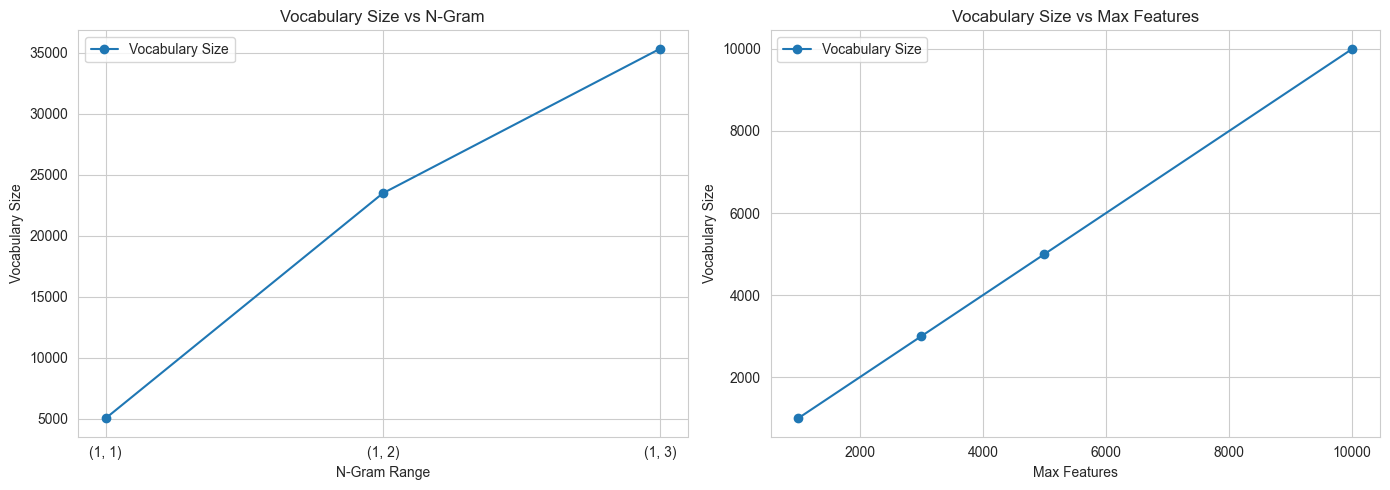

In [330]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# N-Gram experiment
axes[0].plot(
    ngram_experiment_df['N-Gram'],
    ngram_experiment_df['Vocabulary Size'],
    marker='o',
    label='Vocabulary Size'
)

axes[0].set_title('Vocabulary Size vs N-Gram')
axes[0].set_xlabel('N-Gram Range')
axes[0].set_ylabel('Vocabulary Size')
axes[0].legend()

# Max features experiment
axes[1].plot(
    feature_experiment_df['Max Features'],
    feature_experiment_df['Vocabulary Size'],
    marker='o',
    label='Vocabulary Size'
)

axes[1].set_title('Vocabulary Size vs Max Features')
axes[1].set_xlabel('Max Features')
axes[1].set_ylabel('Vocabulary Size')
axes[1].legend()

plt.tight_layout()
plt.show()

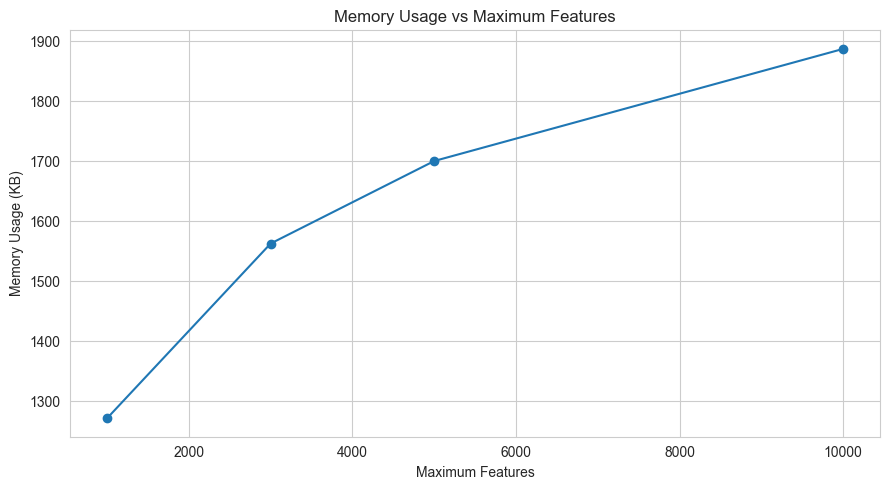

In [331]:
plt.figure(figsize=(9, 5))

plt.plot(
    feature_experiment_df['Max Features'],
    feature_experiment_df['Memory (KB)'],
    marker='o'
)

plt.title('Memory Usage vs Maximum Features')
plt.xlabel('Maximum Features')
plt.ylabel('Memory Usage (KB)')

plt.tight_layout()
plt.show()

# Task 5 – Word Embeddings: Word2Vec, CBoW & Skip-gram

In [332]:
pip install gensim

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\patel\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [333]:
import time
import numpy as np
import pandas as pd

from gensim.models import Word2Vec

In [334]:
# Get token lists for training tweets
train_tokens = df.loc[
    X_train.index, 'filtered_tokens'
].tolist()

# Remove empty token lists
train_tokens = [
    tokens for tokens in train_tokens if len(tokens) > 0
]

# Set random seed
np.random.seed(42)

print("Total Training Tweets:", len(train_tokens))
print("Example Tokens:", train_tokens[0])

Total Training Tweets: 11668
Example Tokens: ['bad', 'weather', 'not', 'excuse', 'not', 'following', 'established', 'luggage', 'procedures', 'noclothesnoinfo']


In [335]:
start_time = time.time()

cbow_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=3,
    sg=0,
    epochs=20,
    seed=42,
    workers=1
)

cbow_time = time.time() - start_time

print("CBoW Training Completed")
print("Vocabulary Size:", len(cbow_model.wv))
print("Vector Shape:", cbow_model.wv.vectors.shape)
print("Training Time:", round(cbow_time, 2), "seconds")

CBoW Training Completed
Vocabulary Size: 3595
Vector Shape: (3595, 100)
Training Time: 1.57 seconds


In [336]:
start_time = time.time()

skipgram_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,
    epochs=20,
    seed=42,
    workers=1
)

skipgram_time = time.time() - start_time

print("Skip-gram Training Completed")
print("Vocabulary Size:", len(skipgram_model.wv))
print("Vector Shape:", skipgram_model.wv.vectors.shape)
print("Training Time:", round(skipgram_time, 2), "seconds")

Skip-gram Training Completed
Vocabulary Size: 3595
Vector Shape: (3595, 100)
Training Time: 3.57 seconds


In [337]:
comparison = pd.DataFrame({
    'Model': ['CBoW', 'Skip-gram'],
    'Vocabulary Size': [
        len(cbow_model.wv),
        len(skipgram_model.wv)
    ],
    'Vector Shape': [
        cbow_model.wv.vectors.shape,
        skipgram_model.wv.vectors.shape
    ],
    'Training Time (Seconds)': [
        round(cbow_time, 2),
        round(skipgram_time, 2)
    ]
})

print(comparison.to_string(index=False))

    Model  Vocabulary Size Vector Shape  Training Time (Seconds)
     CBoW             3595  (3595, 100)                     1.57
Skip-gram             3595  (3595, 100)                     3.57


In [338]:
query_words = [
    'delayed',
    'flight',
    'thanks',
    'rude',
    'luggage',
    'great'
]

def similar_words_table(model, model_name):

    results = []

    for word in query_words:

        if word in model.wv:

            similar = model.wv.most_similar(
                word,
                topn=5
            )

            for similar_word, score in similar:

                results.append({
                    'Model': model_name,
                    'Query Word': word,
                    'Similar Word': similar_word,
                    'Similarity': round(score, 4)
                })

        else:
            print(f"'{word}' is not in {model_name} vocabulary.")

    return results


cbow_results = similar_words_table(
    cbow_model, 'CBoW'
)

skipgram_results = similar_words_table(
    skipgram_model, 'Skip-gram'
)

similarity_df = pd.DataFrame(
    cbow_results + skipgram_results
)

print(similarity_df.to_string(index=False))

    Model Query Word   Similar Word  Similarity
     CBoW    delayed         missed      0.8355
     CBoW    delayed      scheduled      0.7988
     CBoW    delayed            sat      0.7982
     CBoW    delayed         philly      0.7949
     CBoW    delayed        layover      0.7909
     CBoW     flight            flt      0.7370
     CBoW     flight        tuesday      0.6887
     CBoW     flight     connection      0.6842
     CBoW     flight        flights      0.6747
     CBoW     flight            iad      0.6707
     CBoW     thanks          thank      0.8427
     CBoW     thanks    appreciated      0.7419
     CBoW     thanks       recovery      0.7095
     CBoW     thanks     everything      0.7064
     CBoW     thanks           glad      0.6986
     CBoW       rude      unhelpful      0.8744
     CBoW       rude          staff      0.8209
     CBoW       rude      employees      0.8185
     CBoW       rude           desk      0.8174
     CBoW       rude         agents     

In [339]:
from sklearn.metrics.pairwise import cosine_similarity

word_pairs = [
    ('delayed', 'late'),
    ('good', 'great'),
    ('flight', 'banana')
]

def calculate_similarity(model, word1, word2):

    if word1 not in model.wv or word2 not in model.wv:
        return None

    v1 = model.wv[word1].reshape(1, -1)
    v2 = model.wv[word2].reshape(1, -1)

    return cosine_similarity(v1, v2)[0][0]


similarity_results = []

for model_name, model in [
    ('CBoW', cbow_model),
    ('Skip-gram', skipgram_model)
]:

    for word1, word2 in word_pairs:

        score = calculate_similarity(
            model, word1, word2
        )

        similarity_results.append({
            'Model': model_name,
            'Word Pair': f'{word1} - {word2}',
            'Cosine Similarity': (
                round(score, 4)
                if score is not None else 'OOV'
            )
        })

cosine_df = pd.DataFrame(similarity_results)

print(cosine_df.to_string(index=False))

    Model       Word Pair Cosine Similarity
     CBoW  delayed - late            0.6637
     CBoW    good - great            0.5395
     CBoW flight - banana               OOV
Skip-gram  delayed - late            0.4745
Skip-gram    good - great            0.3328
Skip-gram flight - banana               OOV


Original Vector Shape: (60, 100)
Reduced Vector Shape: (60, 2)


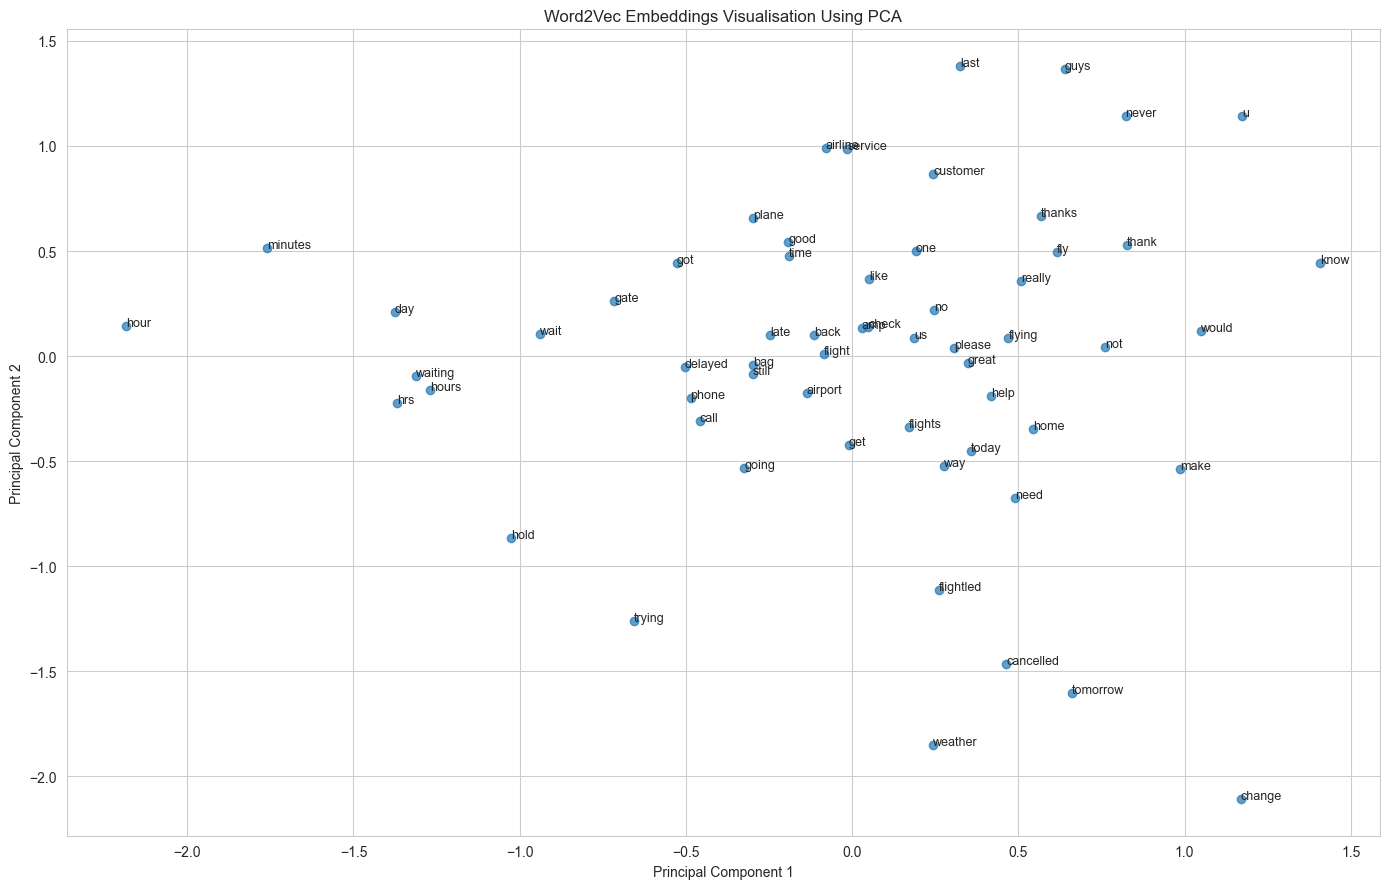

In [340]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Get 60 most frequent words from Skip-gram vocabulary
top_words = [
    word for word, count in
    skipgram_model.wv.key_to_index.items()
][:60]

# Get word vectors
word_vectors = np.array([
    skipgram_model.wv[word]
    for word in top_words
])

print("Original Vector Shape:", word_vectors.shape)

# Apply PCA
pca = PCA(n_components=2)

reduced_vectors = pca.fit_transform(word_vectors)

print("Reduced Vector Shape:", reduced_vectors.shape)

# Create DataFrame
pca_df = pd.DataFrame(
    reduced_vectors,
    columns=['PC1', 'PC2']
)

pca_df['Word'] = top_words

# Plot
plt.figure(figsize=(14, 9))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    alpha=0.7
)

for i, word in enumerate(pca_df['Word']):
    plt.annotate(
        word,
        (pca_df['PC1'][i], pca_df['PC2'][i]),
        fontsize=9
    )

plt.title("Word2Vec Embeddings Visualisation Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.grid(True)
plt.tight_layout()
plt.show()

In [341]:
def doc_vector(tokens, model):

    vectors = []

    for word in tokens:

        if word in model.wv:
            vectors.append(model.wv[word])

    # Return zero vector if no word is available
    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    # Average word vectors
    return np.mean(vectors, axis=0)

In [342]:
# Change this after inspecting Section 5.4
better_model = skipgram_model

print("Selected Word2Vec Model:", 
      "Skip-gram" if better_model is skipgram_model else "CBoW")

Selected Word2Vec Model: Skip-gram


In [343]:
# Get training tokens using the training indices
train_tokens_final = df.loc[
    X_train.index, 'filtered_tokens'
].tolist()

# Convert each tweet into a document vector
X_train_w2v = np.array([
    doc_vector(tokens, better_model)
    for tokens in train_tokens_final
])

print("Training Word2Vec Shape:", X_train_w2v.shape)

Training Word2Vec Shape: (11683, 100)


In [344]:
# Get testing tokens
test_tokens_final = df.loc[
    X_test.index, 'filtered_tokens'
].tolist()

# Convert test tweets into vectors
X_test_w2v = np.array([
    doc_vector(tokens, better_model)
    for tokens in test_tokens_final
])

print("Testing Word2Vec Shape:", X_test_w2v.shape)

Testing Word2Vec Shape: (2921, 100)


In [345]:
# Display first document vector
print("First Document Vector:")
print(X_train_w2v[0])

# Check vector dimensions
print("\nVector Dimensions:",
      X_train_w2v.shape[1])

# Check for zero vectors
zero_vectors = np.all(X_train_w2v == 0, axis=1)

print("Zero Training Vectors:", zero_vectors.sum())

First Document Vector:
[ 2.24635094e-01  8.27802122e-02 -2.76648905e-02 -2.34040916e-02
 -2.51278788e-01  3.40382338e-01 -8.51532444e-02  2.28712440e-01
 -8.49720910e-02 -1.91247493e-01 -5.18470824e-01  1.60933226e-01
 -9.42726061e-02  1.88974708e-01 -3.31693515e-03  5.16882949e-02
 -6.35832101e-02 -3.48610729e-01 -2.32818723e-01 -2.50960328e-03
 -2.18994007e-01  1.33010507e-01 -9.53757837e-02  3.60096246e-01
  2.77562976e-01 -6.64340556e-02 -2.19343722e-01  1.69754684e-01
 -8.58045742e-02 -1.74840346e-01 -3.10781896e-02 -7.62512907e-02
 -9.90897417e-02 -1.71627566e-01  8.31591412e-02  2.51843408e-03
 -7.86289424e-02 -4.88779902e-01  7.01218173e-02  1.22924440e-01
  4.76102680e-02 -1.23595027e-02  1.01819605e-01 -3.41998339e-01
  6.98109716e-02  1.44908458e-01  1.80464059e-01  6.90034404e-02
  2.60724843e-01 -2.85776198e-01  1.32100388e-01 -3.71246099e-01
  1.62271619e-01 -1.85754359e-01  1.77928954e-01 -2.65827715e-01
  4.54256050e-02  1.41981825e-01  6.27452582e-02  2.78493315e-01
 -

# Task 6 – Text Classification Pipeline & Approach Comparison

In [346]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create baseline pipeline
baseline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2
    )),

    ('clf', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train model
baseline_pipeline.fit(X_train, y_train)

# Predict test data
y_pred_baseline = baseline_pipeline.predict(X_test)

print("Baseline Model Training Completed!")

Baseline Model Training Completed!


In [347]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:",
      accuracy_score(y_test, y_pred_baseline))

print("Macro-F1:",
      f1_score(y_test, y_pred_baseline, average='macro'))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_baseline,
    zero_division=0
))

Accuracy: 0.7918521054433413
Macro-F1: 0.7401559616316415

Classification Report:
              precision    recall  f1-score   support

    negative       0.88      0.85      0.87      1832
     neutral       0.60      0.67      0.63       618
    positive       0.73      0.71      0.72       471

    accuracy                           0.79      2921
   macro avg       0.74      0.74      0.74      2921
weighted avg       0.80      0.79      0.79      2921



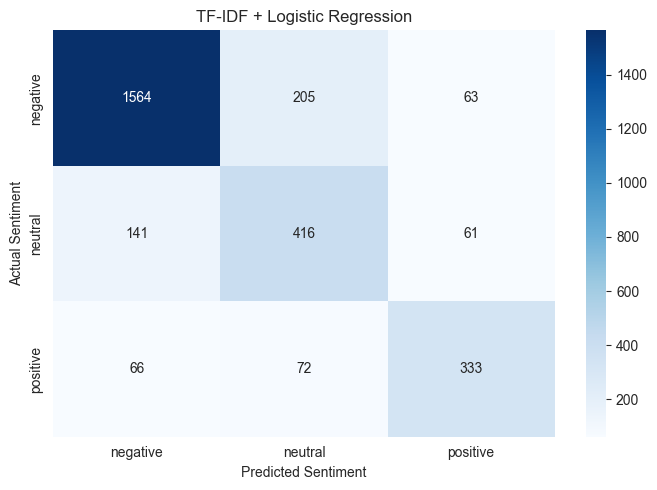

In [348]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = ['negative', 'neutral', 'positive']

cm = confusion_matrix(
    y_test,
    y_pred_baseline,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title("TF-IDF + Logistic Regression")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

In [349]:
import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

models = {
    'BoW + Naive Bayes': Pipeline([
        ('vectorizer', CountVectorizer(min_df=2)),
        ('classifier', MultinomialNB())
    ]),

    'BoW + Logistic Regression': Pipeline([
        ('vectorizer', CountVectorizer(min_df=2)),
        ('classifier', LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ))
    ]),

    'TF-IDF Unigram + LR': Pipeline([
        ('vectorizer', TfidfVectorizer(
            ngram_range=(1, 1),
            min_df=2
        )),
        ('classifier', LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ))
    ]),

    'TF-IDF Bigram + LR': Pipeline([
        ('vectorizer', TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2
        )),
        ('classifier', LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ))
    ])
}

model_results = []
trained_models = {}
model_predictions = {}

for name, model in models.items():

    start = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start

    predictions = model.predict(X_test)

    trained_models[name] = model
    model_predictions[name] = predictions

    model_results.append({
        'Features + Classifier': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Macro-F1': f1_score(
            y_test, predictions, average='macro'
        ),
        'Precision (Negative)': precision_score(
            y_test, predictions,
            labels=['negative'],
            average='macro',
            zero_division=0
        ),
        'Recall (Positive)': recall_score(
            y_test, predictions,
            labels=['positive'],
            average='macro',
            zero_division=0
        ),
        'Training Time': round(training_time, 2)
    })

print("Four sparse-text models trained.")

Four sparse-text models trained.


In [350]:
start = time.time()

w2v_classifier = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

w2v_classifier.fit(X_train_w2v, y_train)

w2v_training_time = time.time() - start

y_pred_w2v = w2v_classifier.predict(X_test_w2v)

trained_models['Word2Vec + Logistic Regression'] = w2v_classifier
model_predictions['Word2Vec + Logistic Regression'] = y_pred_w2v

model_results.append({
    'Features + Classifier': 'Word2Vec + Logistic Regression',
    'Accuracy': accuracy_score(y_test, y_pred_w2v),
    'Macro-F1': f1_score(
        y_test, y_pred_w2v, average='macro'
    ),
    'Precision (Negative)': precision_score(
        y_test, y_pred_w2v,
        labels=['negative'],
        average='macro',
        zero_division=0
    ),
    'Recall (Positive)': recall_score(
        y_test, y_pred_w2v,
        labels=['positive'],
        average='macro',
        zero_division=0
    ),
    'Training Time': round(w2v_training_time, 2)
})

results_df = pd.DataFrame(model_results)

print(results_df.round(4).to_string(index=False))

         Features + Classifier  Accuracy  Macro-F1  Precision (Negative)  Recall (Positive)  Training Time
             BoW + Naive Bayes    0.7754    0.6958                0.8089             0.6285           0.11
     BoW + Logistic Regression    0.7682    0.7204                0.8988             0.7240           0.45
           TF-IDF Unigram + LR    0.7679    0.7211                0.8904             0.7134           0.33
            TF-IDF Bigram + LR    0.7919    0.7402                0.8831             0.7070           0.69
Word2Vec + Logistic Regression    0.7117    0.6588                0.8648             0.6943           0.17


In [351]:
best_row = results_df.loc[
    results_df['Macro-F1'].idxmax()
]

best_model_name = best_row['Features + Classifier']

print("Best Model:", best_model_name)
print("Best Macro-F1:", round(best_row['Macro-F1'], 4))

Best Model: TF-IDF Bigram + LR
Best Macro-F1: 0.7402


In [352]:
all_predictions = {
    'Heuristic': y_pred_heuristic,
    'API-based VADER': y_pred_vader,
    'BoW + Naive Bayes': model_predictions['BoW + Naive Bayes'],
    'BoW + Logistic Regression': model_predictions['BoW + Logistic Regression'],
    'TF-IDF Unigram': model_predictions['TF-IDF Unigram + LR'],
    'TF-IDF + Bigram': model_predictions['TF-IDF Bigram + LR'],
    'Word2Vec': y_pred_w2v
}

comparison_results = []

for name, predictions in all_predictions.items():

    comparison_results.append({
        'Approach': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Macro-F1': f1_score(
            y_test, predictions, average='macro'
        )
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by='Macro-F1',
    ascending=False
)

print(comparison_df.round(4).to_string(index=False))

                 Approach  Accuracy  Macro-F1
          TF-IDF + Bigram    0.7919    0.7402
           TF-IDF Unigram    0.7679    0.7211
BoW + Logistic Regression    0.7682    0.7204
        BoW + Naive Bayes    0.7754    0.6958
                 Word2Vec    0.7117    0.6588
                Heuristic    0.4974    0.5234
          API-based VADER    0.5375    0.5078


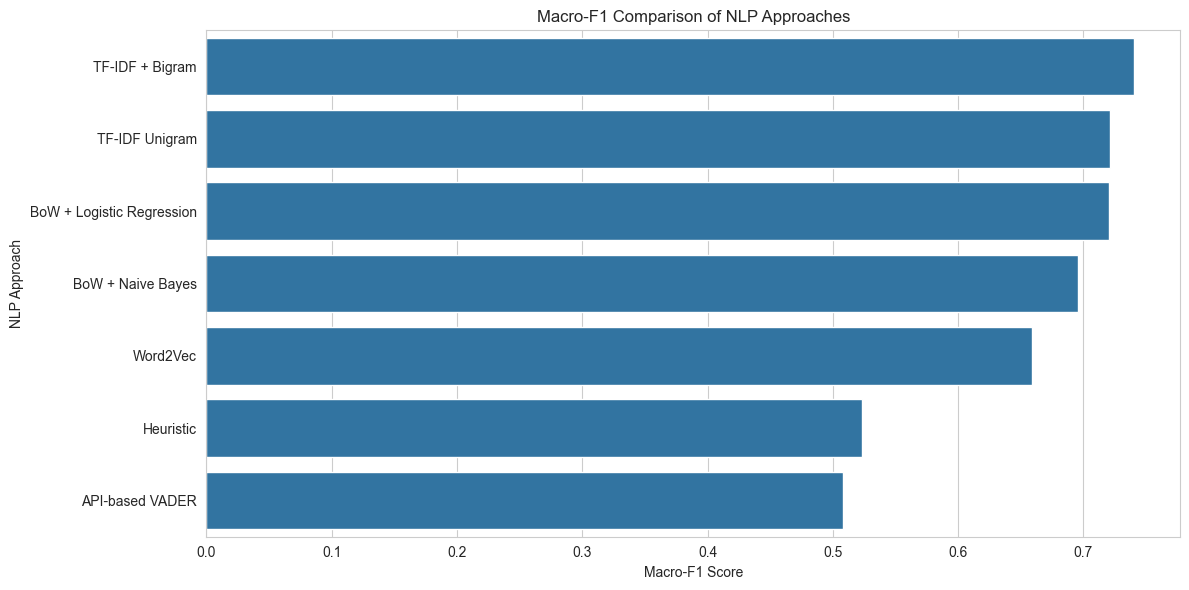

In [353]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_df,
    x='Macro-F1',
    y='Approach'
)

plt.title("Macro-F1 Comparison of NLP Approaches")
plt.xlabel("Macro-F1 Score")
plt.ylabel("NLP Approach")

plt.tight_layout()
plt.show()

In [354]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Select best among the four text-based pipelines
text_model_names = list(models.keys())

best_text_name = max(
    text_model_names,
    key=lambda name: next(
        r['Macro-F1'] for r in model_results
        if r['Features + Classifier'] == name
    )
)

best_pipeline = trained_models[best_text_name]

print("Best Text Pipeline:", best_text_name)

# Stratified 5-fold cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    best_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring='f1_macro',
    n_jobs=-1
)

print("\nCross Validation Scores:", cv_scores)
print("Mean Macro-F1:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

# Compare with test score
test_macro_f1 = f1_score(
    y_test,
    best_pipeline.predict(X_test),
    average='macro'
)

print("Test Macro-F1:", round(test_macro_f1, 4))

Best Text Pipeline: TF-IDF Bigram + LR

Cross Validation Scores: [0.73335841 0.74750259 0.7278473  0.75968855 0.73167969]
Mean Macro-F1: 0.74
Standard Deviation: 0.0119
Test Macro-F1: 0.7402


In [355]:
# Select the best text pipeline
y_pred_best = best_pipeline.predict(X_test)

# Prediction probabilities
probabilities = best_pipeline.predict_proba(X_test)

# Maximum probability for each prediction
max_probabilities = probabilities.max(axis=1)

# Create error DataFrame
error_analysis = pd.DataFrame({
    'Original Tweet': df.loc[X_test.index, 'text'],
    'True Sentiment': y_test,
    'Predicted Sentiment': y_pred_best,
    'Probability': max_probabilities
}, index=X_test.index)

# Select incorrect predictions
misclassified = error_analysis[
    error_analysis['True Sentiment'] !=
    error_analysis['Predicted Sentiment']
]

# Display 8 errors
print(
    misclassified.head(8).to_string(index=False)
)

                                                                                                                          Original Tweet True Sentiment Predicted Sentiment  Probability
                                                                                @USAirways call Gate D9 in CLT and get me on this flight        neutral            negative     0.613986
                @united have reported it.  Still in Istanbul at the moment apparently.  On the other plane haha.  Hats off to the pilot!       positive            negative     0.548856
                                                                                                           @VirginAmerica That's classy.       positive             neutral     0.472577
                                                           @united Thanks for the lack of help and the canned response from the 1K desk!       negative            positive     0.509638
@USAirways I booked a flight yesterday but didnt receive an email confirmat

In [356]:
import joblib
import sklearn

# Save selected best text pipeline
joblib.dump(
    best_pipeline,
    'sentiment_model.joblib'
)

print("Model Saved Successfully!")

# Print sklearn version
print("Scikit-learn Version:", sklearn.__version__)

Model Saved Successfully!
Scikit-learn Version: 1.9.1


In [357]:
# Load saved model
loaded_model = joblib.load(
    'sentiment_model.joblib'
)

print("Model Loaded Successfully!")

Model Loaded Successfully!


In [358]:
new_tweets = [
    "The flight was amazing and the staff was friendly",
    "My flight is delayed and customer service is terrible",
    "The airline provided information about my booking"
]

# Apply the same cleaning function from Task 2
new_cleaned_tweets = [
    clean_text(tweet)
    for tweet in new_tweets
]

# Predict sentiment
new_predictions = loaded_model.predict(
    new_cleaned_tweets
)

# Get prediction probabilities
new_probabilities = loaded_model.predict_proba(
    new_cleaned_tweets
)

# Display results
for i, tweet in enumerate(new_tweets):

    print("\nOriginal Tweet:", tweet)

    print("Cleaned Tweet:", new_cleaned_tweets[i])

    print("Predicted Sentiment:", new_predictions[i])

    print(
        "Probabilities:",
        dict(zip(
            loaded_model.classes_,
            new_probabilities[i].round(4)
        ))
    )


Original Tweet: The flight was amazing and the staff was friendly
Cleaned Tweet: the flight was amazing and the staff was friendly
Predicted Sentiment: positive
Probabilities: {'negative': 0.1153, 'neutral': 0.0331, 'positive': 0.8517}

Original Tweet: My flight is delayed and customer service is terrible
Cleaned Tweet: my flight is delayed and customer service is terrible
Predicted Sentiment: negative
Probabilities: {'negative': 0.9754, 'neutral': 0.0093, 'positive': 0.0153}

Original Tweet: The airline provided information about my booking
Cleaned Tweet: the airline provided information about my booking
Predicted Sentiment: negative
Probabilities: {'negative': 0.3943, 'neutral': 0.3549, 'positive': 0.2508}


# Task 7 – POS Tagging (Part of Speech Tagging)

In [359]:
import nltk
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk import pos_tag

nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')

# For newer NLTK versions, if required:
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to C:\Users\patel/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\patel/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\patel/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\patel/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\patel/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\patel/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_dat

True

In [360]:
sample_tweets = df[
    df['clean_text'].str.strip().ne('')
].sample(5, random_state=42)

sample_tweets[['text', 'clean_text', 'airline_sentiment']]

,text,clean_text,airline_sentiment
169,@VirginAmerica to jump into the Dallas-Austin ...,to jump into the dallas austin market,neutral
2054,@united nice. I wonder how you pick who to res...,nice i wonder how you pick who to respond to m...,negative
10437,@USAirways BF has been stuck in CLT all day. I...,bf has been stuck in clt all day is the lounge...,negative
9457,"@USAirways horrible service, wrong plane arriv...",horrible service wrong plane arrived many conf...,negative
14512,@AmericanAir. You neglected to mention the $20...,you neglected to mention the fee per ticket i ...,negative


In [361]:
for index, row in sample_tweets.iterrows():

    tokens = word_tokenize(row['clean_text'])
    tagged_words = pos_tag(tokens)

    print("\nOriginal Tweet:")
    print(row['text'])

    print("POS Tags:")
    print(tagged_words)

    print("Sentiment:", row['airline_sentiment'])
    print("-" * 70)


Original Tweet:
@VirginAmerica to jump into the Dallas-Austin market - @Dallas_News http://t.co/EwwGi97gdx
POS Tags:
[('to', 'TO'), ('jump', 'VB'), ('into', 'IN'), ('the', 'DT'), ('dallas', 'NNS'), ('austin', 'VBP'), ('market', 'NN')]
Sentiment: neutral
----------------------------------------------------------------------

Original Tweet:
@united nice. I wonder how you pick who to respond to? Maybe only happy customers are easier. I wonder how many of those you have left.
POS Tags:
[('nice', 'JJ'), ('i', 'NN'), ('wonder', 'VBP'), ('how', 'WRB'), ('you', 'PRP'), ('pick', 'VBP'), ('who', 'WP'), ('to', 'TO'), ('respond', 'VB'), ('to', 'TO'), ('maybe', 'RB'), ('only', 'RB'), ('happy', 'JJ'), ('customers', 'NNS'), ('are', 'VBP'), ('easier', 'JJR'), ('i', 'JJ'), ('wonder', 'VBP'), ('how', 'WRB'), ('many', 'JJ'), ('of', 'IN'), ('those', 'DT'), ('you', 'PRP'), ('have', 'VBP'), ('left', 'VBN')]
Sentiment: negative
----------------------------------------------------------------------

Origina

In [362]:
sentences = [
    "I park my car near the airport.",
    "The park is beautiful."
]

for sentence in sentences:

    tokens = word_tokenize(sentence)
    tagged_words = pos_tag(tokens)

    print("\nSentence:", sentence)
    print("POS Tags:", tagged_words)


Sentence: I park my car near the airport.
POS Tags: [('I', 'PRP'), ('park', 'VBP'), ('my', 'PRP$'), ('car', 'NN'), ('near', 'IN'), ('the', 'DT'), ('airport', 'NN'), ('.', '.')]

Sentence: The park is beautiful.
POS Tags: [('The', 'DT'), ('park', 'NN'), ('is', 'VBZ'), ('beautiful', 'JJ'), ('.', '.')]


In [363]:
pos_sample = pd.DataFrame({
    'text': X_train,
    'sentiment': y_train
}).sample(n=min(2000, len(X_train)), random_state=42)

pos_sample.head()

,text,sentiment
14613,i used the call back feature with an operator ...,negative
6985,no they didn t our fleet s on fleek,neutral
10401,that s clever its clear you need more agents m...,negative
9392,too late flight,negative
1703,ridiculous i have to be refunded whenever i ge...,negative


In [364]:
from collections import Counter

pos_results = []

for _, row in pos_sample.iterrows():

    tokens = word_tokenize(row['text'])
    tagged = pos_tag(tokens)

    total_words = len(tagged)

    counts = Counter(tag for word, tag in tagged)

    if total_words == 0:
        continue

    adjectives = sum(
        count for tag, count in counts.items()
        if tag.startswith('JJ')
    )

    adverbs = sum(
        count for tag, count in counts.items()
        if tag.startswith('RB')
    )

    verbs = sum(
        count for tag, count in counts.items()
        if tag.startswith('VB')
    )

    nouns = sum(
        count for tag, count in counts.items()
        if tag.startswith('NN')
    )

    pos_results.append({
        'sentiment': row['sentiment'],
        'Adjectives': adjectives / total_words,
        'Adverbs': adverbs / total_words,
        'Verbs': verbs / total_words,
        'Nouns': nouns / total_words
    })

pos_df = pd.DataFrame(pos_results)

pos_summary = pos_df.groupby('sentiment')[
    ['Adjectives', 'Adverbs', 'Verbs', 'Nouns']
].mean()

pos_summary

,Adjectives,Adverbs,Verbs,Nouns
sentiment,,,,
negative,0.081432,0.063993,0.219095,0.287348
neutral,0.082414,0.053719,0.214597,0.303411
positive,0.097178,0.063932,0.186503,0.334928


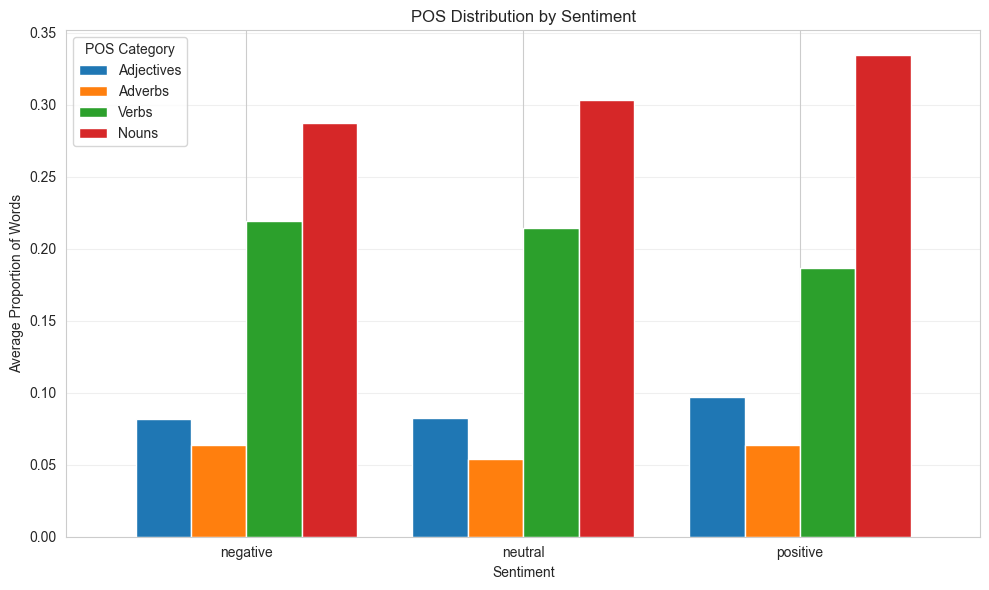

In [365]:
import matplotlib.pyplot as plt

pos_summary.plot(
    kind='bar',
    figsize=(10, 6),
    width=0.8
)

plt.title('POS Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Average Proportion of Words')
plt.xticks(rotation=0)
plt.legend(title='POS Category')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [366]:
negative_adjectives = []
positive_adjectives = []

for _, row in pos_sample.iterrows():

    tokens = word_tokenize(row['text'])
    tagged = pos_tag(tokens)

    adjectives = [
        word.lower()
        for word, tag in tagged
        if tag.startswith('JJ')
    ]

    if row['sentiment'] == 'negative':
        negative_adjectives.extend(adjectives)

    elif row['sentiment'] == 'positive':
        positive_adjectives.extend(adjectives)


print("Top 10 Negative Adjectives:")
print(Counter(negative_adjectives).most_common(10))

print("\nTop 10 Positive Adjectives:")
print(Counter(positive_adjectives).most_common(10))

Top 10 Negative Adjectives:
[('i', 135), ('late', 44), ('t', 43), ('last', 40), ('due', 32), ('more', 30), ('flightled', 26), ('united', 26), ('worst', 25), ('bad', 21)]

Top 10 Positive Adjectives:
[('great', 33), ('i', 20), ('best', 15), ('awesome', 13), ('new', 10), ('much', 9), ('helpful', 9), ('nice', 8), ('good', 8), ('wonderful', 8)]


In [367]:
from nltk.tokenize import word_tokenize
from nltk import pos_tag

NEGATION_WORDS = {'not', 'no', 'nor', 'never'}

def pos_filter_text(text):

    tokens = word_tokenize(str(text))
    tagged = pos_tag(tokens)

    selected_words = []

    for word, tag in tagged:

        if (tag.startswith('JJ') or
            tag.startswith('RB') or
            tag.startswith('VB') or
            word.lower() in NEGATION_WORDS):

            selected_words.append(word.lower())

    return ' '.join(selected_words)

In [368]:
X_train_pos = X_train.apply(pos_filter_text)
X_test_pos = X_test.apply(pos_filter_text)

print("Original Text:")
print(X_train.iloc[0])

print("\nPOS Filtered Text:")
print(X_train_pos.iloc[0])

Original Text:
and bad weather should not be an excuse for not following established luggage procedures noclothesnoinfo

POS Filtered Text:
bad not be not following established noclothesnoinfo


In [369]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Full-text pipeline
full_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2
    )),
    ('clf', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# POS-filtered pipeline
pos_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2
    )),
    ('clf', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train full-text model
full_pipeline.fit(X_train, y_train)

# Train POS-filtered model
pos_pipeline.fit(X_train_pos, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['negative','neutral','positive']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


In [370]:
# Full-text predictions
full_pred = full_pipeline.predict(X_test)

# POS-filtered predictions
pos_pred = pos_pipeline.predict(X_test_pos)

# Results
results = pd.DataFrame({
    'Model': ['Full Text', 'POS Filtered'],
    'Accuracy': [
        accuracy_score(y_test, full_pred),
        accuracy_score(y_test, pos_pred)
    ],
    'Macro F1': [
        f1_score(y_test, full_pred, average='macro'),
        f1_score(y_test, pos_pred, average='macro')
    ]
})

results

,Model,Accuracy,Macro F1
0,Full Text,0.791852,0.740156
1,POS Filtered,0.705923,0.642892


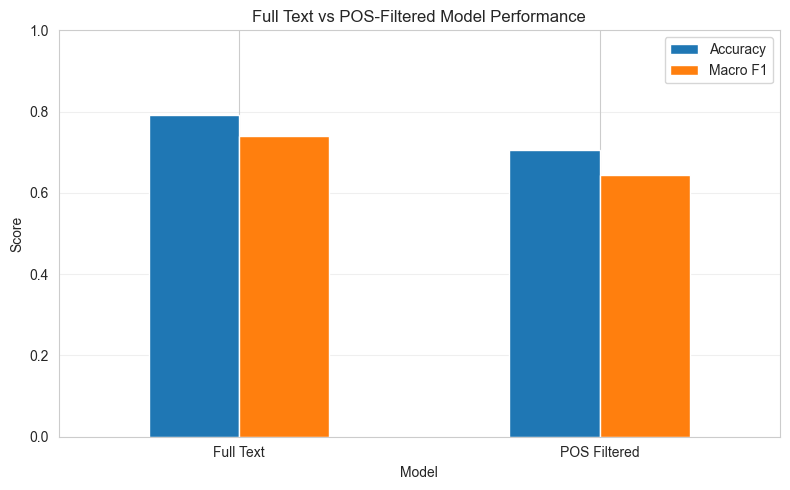

In [371]:
results.set_index('Model')[['Accuracy', 'Macro F1']].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Full Text vs POS-Filtered Model Performance')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [372]:
import re

def clean_text(text):
    if text is None:
        return ""

    text = str(text).lower()

    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text


positive_words = {
    "good", "great", "excellent", "happy", "love",
    "amazing", "best", "wonderful", "friendly",
    "helpful", "thanks", "awesome"
}

negative_words = {
    "bad", "worst", "poor", "hate", "angry",
    "terrible", "delayed", "rude", "late",
    "awful", "disappointed", "problem"
}


def heuristic_sentiment(text):

    words = clean_text(text).split()

    pos = sum(word in positive_words for word in words)
    neg = sum(word in negative_words for word in words)

    if pos > neg:
        return "positive"

    elif neg > pos:
        return "negative"

    else:
        return "neutral"

In [373]:
pip install streamlit


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\patel\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [374]:
import sklearn
import streamlit
import nltk
import pandas
import joblib

print("scikit-learn:", sklearn.__version__)
print("streamlit:", streamlit.__version__)
print("nltk:", nltk.__version__)
print("pandas:", pandas.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.9.1
streamlit: 1.67.0
nltk: 3.10.4
pandas: 2.2.3
joblib: 1.6.0
